<a href="https://colab.research.google.com/github/mecoskun/LLM_RAG_Embeddings_Princeton/blob/main/4_embeddings_rag.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Embeddings and RAG: searching and asking questions of a document collection

**Who this is for:** researchers who want to use large language models (LLMs) in their work but do not necessarily have a machine-learning background.

**What you will learn**

1. *How* to turn each document into embeddings, a list of numbers so that similar texts get similar numbers.
2. *How* to map and group documents into topics and search by meaning rather than exact words.
3. *How* to find relevant documents and have the model answer only from them, using RAG (retrieval-augmented generation) systems.
4. Some common failure modes.

This is the third notebook in the series, after **Using LLMs through an API** and **Tinker**.

> **Live vs. read-only.** Cells marked **LIVE** run in the session. Sections marked **READ** are for reading and reference.

## 1. What is an embedding? (READ)

An **embedding model** reads a piece of text and outputs a fixed-length list of numbers (a *vector*), for example 384 numbers. It is trained so that texts with similar meaning end up with similar vectors.

Think of each text as a point in space. Two documents about economic policies land close together; a blog post about the best ice cream shop in Princeton lands far away. **Cosine similarity** measures how closely two vectors point in the same direction: about 1 means "very similar", around 0 means "unrelated".

What embeddings are good at capturing: topic, subject matter, paraphrases ("ice cream" and "frozen cream" land close).

What they are bad at: **negation, sentiment, stance, and numbers.** "I like this ice cream" and "I don't like this ice cream." are about the same topic, so they land close together. We will see this failure live below.

## 2. Setup (LIVE)


Run the following cell to install necessary packages:

`sentence-transformers` -> A library for modeling / interacting with embedding models.

`rank_bm25` -> A library that implements many variations of the BM25 algorithm, which allows searching from a database and ranking the outputs.

`openai` -> A library developed by OpenAI for its models. Now a standardized protocol across most API providers.

`pandas` -> A standard Python library for manipulating CSVs. We'll use this to manage our dataset.

`scikit-learn` -> A standard library for classical machine learning algorithms (e.g., regression, clustering).

`matplotlib` -> A standard library for plotting figures in Python.

In [1]:
%pip install -q sentence-transformers rank_bm25 openai pandas scikit-learn matplotlib

In [2]:
import re, time, os, json
import numpy as np
import pandas as pd



Next, we load the dataset of 300 arXiv papers, 60 from each of the following fields: computer science, physics, mathematics, chemistry, and economics. For each paper, we will later embed its title plus abstract.

Go to the Google Drive folder and download the `arxiv_abstracts.csv` file, if you have not already done so.

- **On Colab:** click the folder icon in the left sidebar, upload the file by dragging and dropping.
- **Elsewhere:** keep the `arxiv_abstracts.csv` in the same folder as this notebook.

In [4]:
papers = pd.read_csv("arxiv_abstracts.csv", dtype={"arxiv_id": str})
docs = (papers.title + ". " + papers.abstract).tolist()   # what we embed: title plus abstract
print(len(papers), "papers")
print(papers.field.value_counts().to_string())
papers[["arxiv_id", "field", "title"]].head()

300 papers
field
Chemistry           60
Computer Science    60
Economics           60
Mathematics         60
Physics             60


,arxiv_id,field,title
0,2610.09151,Chemistry,Coupled Cluster Amplitude Extrapolation in Geo...
1,2609.31728,Chemistry,A Green-function unification of weak interacti...
2,2609.21542,Chemistry,Enriching molecular Raman spectroscopy with vi...
3,2610.29775,Chemistry,Consistent Modeling of SEI Growth via Electron...
4,2610.13649,Chemistry,Electron-Density-Informed Molecular Property P...


## 3. Embed the corpus (LIVE)

For the purpose of this demo, we use **`all-MiniLM-L6-v2`**, a small, fast, widely used English model (about 22 million parameters, 384 numbers per text). It runs comfortably on Colab's free CPU. For a more complex task, we would ideally want to use a larger, more performant embedding model.

The first run also downloads the model (about 90 MB), which takes up to a minute.

In [5]:
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
embedder = SentenceTransformer(EMBED_MODEL, device="cpu")

start = time.time()
E = embedder.encode(docs, normalize_embeddings=True, batch_size=32, show_progress_bar=False)
print(f"Embedded {len(docs)} documents in {time.time() - start:.1f}s. Shape: {E.shape} (documents x numbers)")
print("The first 8 numbers of the first abstract:", np.round(E[0, :8], 3))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedded 300 documents in 47.2s. Shape: (300, 384) (documents x numbers)
The first 8 numbers of the first abstract: [-0.066 -0.03  -0.041  0.041 -0.037 -0.055 -0.035  0.02 ]


You may not understand the content of the abtract from the numbers printed above, but rest assured: the embedding model understands this perfectly well!

## 4. Similarity, a map, and topics (LIVE)

### Which papers are most alike?
Because the vectors are normalized, cosine similarity is just a matrix product.

In [6]:
S = E @ E.T                       # cosine similarity between every pair of papers
np.fill_diagonal(S, -1)           # ignore each paper's similarity with itself
i, j = np.unravel_index(S.argmax(), S.shape)
print(f"Most similar pair (cosine {S[i, j]:.2f}):\n  - {papers.title[i]}\n  - {papers.title[j]}")

Most similar pair (cosine 0.85):
  - Electron-Density-Informed Molecular Property Prediction Using Surrogate Functionals
  - Orbital-Free Surrogate Functionals Yield Transferable Interatomic Potentials and Electron Densities


Now, if you are interested, change the `i` and `j` indices below to find the cosine similarity between any pair of papers of your choice! If you would like to turn off the `print_abstract`, you can set it to `False`

In [7]:
import textwrap

i = 0 # choose a number between 0 and 299 (inclusive)
j = 1 # choose a number between 0 and 299 (inclusive)
print_abstract = True # change to False to hide the abstract

print(f"cosine {S[i, j]:.2f} (higher = more similar):\n")
print(f"Paper 1: {papers.title[i]}\n")
if print_abstract: print(textwrap.fill(f"Abstract: {papers.abstract[i]}\n\n", width=80))

print(f"\nPaper 2: {papers.title[j]}\n")
if print_abstract: print(textwrap.fill(f"Abstract: {papers.abstract[j]}\n\n", width=80))

cosine 0.27 (higher = more similar):

Paper 1: Coupled Cluster Amplitude Extrapolation in Geometry Optimization

Abstract: In this work, we present an amplitude extrapolation ansatz for
geometry optimization that uses calculations from previous steps to construct an
initial guess for the quasi-Newton solver at each new geometry, significantly
accelerating convergence of the coupled-cluster and Lambda solver alike. The
ansatz incorporates a necessary amplitude transformation to mitigate
discontinuities associated with orbital energy crossings at the Hartree-Fock
level of theory, while remaining computational and memory efficient. The method
is tested for a diverse set of medium-sized molecules to demonstrate a
systematic and significant reduction in the number of coupled-cluster iterations
compared to the conventional method.

Paper 2: A Green-function unification of weak interactions with environmental dressing

Abstract: Weak, non-covalent interactions such as electrostatics, inductio

### A 2-D map of the corpus
Each paper has 384 numbers, which we cannot plot. **PCA** (principal component analysis) squeezes them into 2 numbers while keeping as much of the spread as possible. Colors show each paper's arXiv category, which the model never saw.

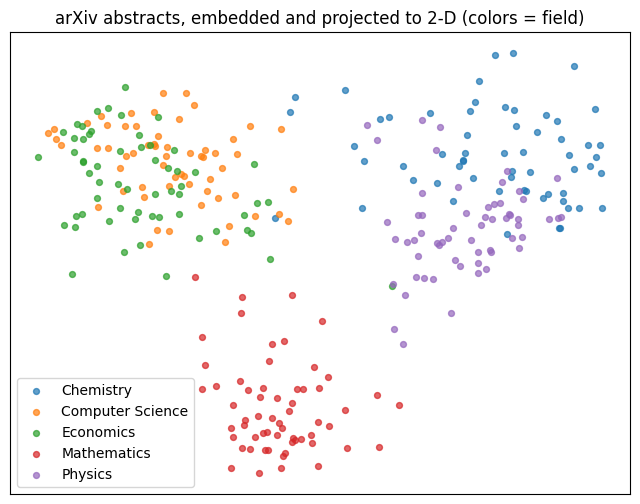

In [8]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(E)
fig, ax = plt.subplots(figsize=(8, 6))
for field in sorted(papers.field.unique()):
    m = (papers.field == field).values
    ax.scatter(xy[m, 0], xy[m, 1], s=18, alpha=0.7, label=field)
ax.set_title("arXiv abstracts, embedded and projected to 2-D (colors = field)")
ax.legend(); ax.set_xticks([]); ax.set_yticks([])
plt.show()

The figure above shows that papers from the same filed are generally mapped in a similar region. However, papers from "Computer Science" (orange) and "Economics" (green) seem to be overlapped with each other. Does this mean that the embedding model cannot distinguish between the two fields?

Let's do a 2-dimensional PCA again, but with just the papers from the two fields.

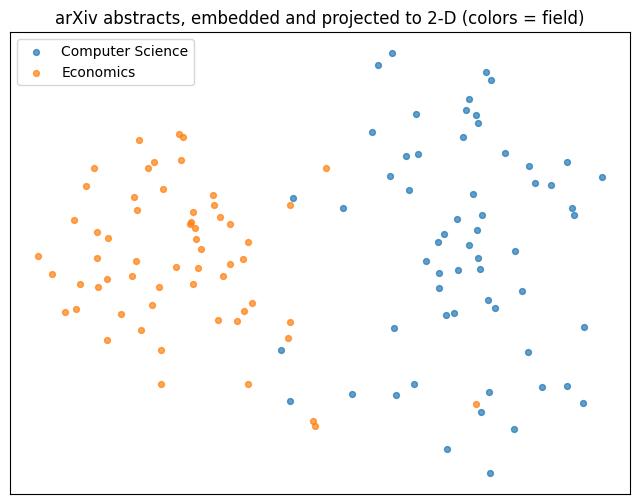

In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

papers_subset = papers[papers.field.isin(["Computer Science", "Economics"])]
E_subset = E[papers_subset.index]

xy_subset = PCA(n_components=2, random_state=0).fit_transform(E_subset)
fig, ax = plt.subplots(figsize=(8, 6))
for field in sorted(papers_subset.field.unique()):
    m = (papers_subset.field == field).values
    ax.scatter(xy_subset[m, 0], xy_subset[m, 1], s=18, alpha=0.7, label=field)
ax.set_title("arXiv abstracts, embedded and projected to 2-D (colors = field)")
ax.legend(); ax.set_xticks([]); ax.set_yticks([])
plt.show()

So the figure above shows that our embedding model (remember that it only had 22M parameters!) is able to distinguish between computer science and economics too.

### Discovering topics with clustering
**KMeans** groups the points into *k* clusters without looking at the field labels. Reading a few titles per cluster tells us what each cluster is about, a quick alternative to classic topic models such as LDA. The number of clusters is a choice you make, not something the data tells you. We pick 5 because we know there are 5 fields.

In [10]:
from sklearn.cluster import KMeans

K = 5
papers["cluster"] = KMeans(n_clusters=K, random_state=0, n_init=10).fit_predict(E)
for c in range(K):
    members = papers[papers.cluster == c]
    centre = E[members.index].mean(axis=0)
    closest = members.index[np.argsort(-(E[members.index] @ centre))[:3]]
    print(f"\nCluster {c} ({len(members)} papers; most common field: {members.field.mode()[0]})")
    for k in closest:
        print("   -", papers.title[k][:100])

# How well do the clusters match the real fields? (rows = field, columns = cluster)
pd.crosstab(papers.field, papers.cluster)


Cluster 0 (61 papers; most common field: Mathematics)
   - Ramified convolution and monodromy bases for symmetrizable Kac--Moody algebras
   - Leafrians, Poisson structures, and Frobenius splittings on moduli spaces
   - Derived equivalence classification of twisted and generalized multifold extensions of affine type

Cluster 1 (58 papers; most common field: Computer Science)
   - VerifierBench: Benchmarking the Generation of Executable Verifiers for LLM Agents
   - RELAY: Scaling Historical Build Restoration through Rule Reuse and Agentic Repair
   - FaaSpot: Fault-Tolerant Serverless Workflow Execution on Spot Instances

Cluster 2 (54 papers; most common field: Physics)
   - Cosmology of self-interacting ultralight dark matter: simultaneous shifts in the Hubble constant and
   - A Catalog of Spectral Properties for DESI DR1 Quasars
   - Constraints on interacting dark energy with a constant equation of state in light of DESI DR2: The r

Cluster 3 (64 papers; most common field: Chemi

cluster,0,1,2,3,4
field,,,,,
Chemistry,0,1,1,58,0
Computer Science,0,56,0,0,4
Economics,0,1,0,1,58
Mathematics,59,0,0,0,1
Physics,2,0,53,5,0


The previous cell should have printed a table that compares the clusters with the true fields. How well did the clustering algorithm do?

Most papers land in their field's cluster; the few that don't are often interesting (a physics paper written like mathematics, say).

Now try 3 or 8 and see what changes.

In [11]:
K = 3
papers["cluster"] = KMeans(n_clusters=K, random_state=0, n_init=10).fit_predict(E)
for c in range(K):
    members = papers[papers.cluster == c]
    centre = E[members.index].mean(axis=0)
    closest = members.index[np.argsort(-(E[members.index] @ centre))[:3]]
    print(f"\nCluster {c} ({len(members)} papers; most common field: {members.field.mode()[0]})")
    for k in closest:
        print("   -", papers.title[k][:100])

pd.crosstab(papers.field, papers.cluster)


Cluster 0 (123 papers; most common field: Computer Science)
   - VerifierBench: Benchmarking the Generation of Executable Verifiers for LLM Agents
   - Partial Identification under Imperfect Measurement: A Distributionally Robust Approach
   - When Does Randomized Oversight Align AI Agents That Can Conceal?

Cluster 1 (62 papers; most common field: Mathematics)
   - Ramified convolution and monodromy bases for symmetrizable Kac--Moody algebras
   - Leafrians, Poisson structures, and Frobenius splittings on moduli spaces
   - Derived equivalence classification of twisted and generalized multifold extensions of affine type

Cluster 2 (115 papers; most common field: Physics)
   - Nonuniform Screening Reshapes Collective Excitons in Molecular Aggregates from Stochastic Bethe-Salp
   - Machine-learned Laplacian-level density functional from exact exchange-correlation potentials and en
   - Constraints on interacting dark energy with a constant equation of state in light of DESI DR2: The r


cluster,0,1,2
field,,,
Chemistry,3,0,57
Computer Science,60,0,0
Economics,59,1,0
Mathematics,1,59,0
Physics,0,2,58


In [12]:
K = 8
papers["cluster"] = KMeans(n_clusters=K, random_state=0, n_init=10).fit_predict(E)
for c in range(K):
    members = papers[papers.cluster == c]
    centre = E[members.index].mean(axis=0)
    closest = members.index[np.argsort(-(E[members.index] @ centre))[:3]]
    print(f"\nCluster {c} ({len(members)} papers; most common field: {members.field.mode()[0]})")
    for k in closest:
        print("   -", papers.title[k][:100])

pd.crosstab(papers.field, papers.cluster)


Cluster 0 (26 papers; most common field: Mathematics)
   - Positive sectional curvature on exotic spheres in infinitely many dimensions
   - Triangulation of orbifolds with corners
   - Topological mapping class groups of non-simply connected 4-manifolds

Cluster 1 (63 papers; most common field: Chemistry)
   - Orbital-Free Surrogate Functionals Yield Transferable Interatomic Potentials and Electron Densities
   - Machine-learned Laplacian-level density functional from exact exchange-correlation potentials and en
   - On the importance of multi-configurational and exchange effects in molecular aggregates

Cluster 2 (55 papers; most common field: Economics)
   - Random Disclosure Costs: A Unified Theory of Disclosure
   - Memory Manipulation
   - On the Optimality of Mental Accounting

Cluster 3 (54 papers; most common field: Physics)
   - Cosmology of self-interacting ultralight dark matter: simultaneous shifts in the Hubble constant and
   - A Catalog of Spectral Properties for DESI 

cluster,0,1,2,3,4,5,6,7
field,,,,,,,,
Chemistry,0,58,0,0,2,0,0,0
Computer Science,0,0,2,0,28,0,0,30
Economics,0,0,53,0,4,0,3,0
Mathematics,25,0,0,0,0,22,13,0
Physics,1,5,0,54,0,0,0,0


## 5. Search by meaning vs. by keywords (LIVE)

**Keyword search** (here **BM25**, the classic ranking behind most search boxes) scores documents by shared words. **Semantic search** embeds the query and returns the nearest documents, so it can match paraphrases with no words in common. Compare the two on the same queries.

In [13]:
from rank_bm25 import BM25Okapi

tokenize = lambda s: re.findall(r"[a-z0-9]+", s.lower())
bm25 = BM25Okapi([tokenize(d) for d in docs])

def semantic_search(query, k=5):
    q = embedder.encode([query], normalize_embeddings=True)[0]
    scores = E @ q
    return list(np.argsort(-scores)[:k]), scores

def keyword_search(query, k=5):
    scores = bm25.get_scores(tokenize(query))
    return list(np.argsort(-scores)[:k]), scores

for query in ["invisible matter in the universe", "who wins when people bargain or vote", "simulating how molecules absorb light"]:
    print(f"\n\nQUERY: {query}\n")
    for name, fn in [("semantic", semantic_search), ("keyword ", keyword_search)]:
        idx, _ = fn(query, k=3)
        print(f"  {name}:")
        for k in idx:
            print("     -", papers.title[k][:95])



QUERY: invisible matter in the universe

  semantic:
     - Cosmology of self-interacting ultralight dark matter: simultaneous shifts in the Hubble constan
     - ULTRAMAN: A Proposed ultrasound detector for macroscopic dark matter
     - Detectable Dark Matter Freeze-in via Low Reheating
  keyword :
     - The Accommodation Trap: Survival Dependence, Communication, and the Allocation of Invisible Wor
     - Spherization of the velocity field of cosmological perturbations near density extrema
     - GPAge: a Global Parameterization based on cosmic Age for some unified early-time and late-time 


QUERY: who wins when people bargain or vote

  semantic:
     - Strategic Voting Axioms for Multiwinner Elections
     - Strategy-proof voting schemes under single-peaked preferences over intervals
     - Anchor-proofness in Voting with Ranked Ballots
  keyword :
     - Biased Agents, Extreme Beliefs: Motivated Reasoning Under Competing Models
     - Every Alarm Has a Cause: An Open Generator

Is there any result that stands out? Is semantic search always reliable?

## 6. A mini RAG system with citations (LIVE)

**RAG** (retrieval-augmented generation) answers a question in two steps:

1. **Retrieve:** embed the question and find the 5 most similar abstracts (the search above).
2. **Generate:** send the question *plus those 5 abstracts* to a language model, instructing it to answer only from them and to cite the arXiv ID of every source it uses.

Everything except step 2 runs free on Colab. Our "index" is just the matrix `E` in memory, which is fine for a few thousand documents. Abstracts are short, so each abstract is one **chunk**; for long documents (papers, reports, transcripts) you would first split them into passages of a few hundred words.


In this demo, we, the users, are the ones interacting with the embedding model. We handcraft the pipeline to retrieve the relevant papers titles+abstracts and pass off the "augmented" query to the main LLM. However, most of the more modern AI agents are able to interact directly with the embedding model. If you have a database and an embedding model hosted locally on your setup, the main LLM can directly search for relevant information via tool calls.

For this part, you need an OpenRouter API key, which works like a password that is billed. In the session, everyone gets their own key with a small spending limit, so **please keep the limits in the code below**: they stop a mistake from using up your key.

- **On Colab:** click the key icon in the left sidebar, add a secret named `OPENROUTER_API_KEY`, and turn on notebook access.
- **Elsewhere:** set an environment variable by typing `export OPENROUTER_API_KEY=sk...` into the terminal.

The next cell loads the API key you entered.

In [14]:
import os
from openai import OpenAI

def get_key():
    try:
        from google.colab import userdata          # works only on Colab
        return userdata.get("OPENROUTER_API_KEY")
    except Exception:
        return os.environ.get("OPENROUTER_API_KEY")

API_KEY = get_key()
API_ENABLED = bool(API_KEY)
print("API key found." if API_ENABLED else "No API key found: the RAG answer cells will be skipped.")

client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=API_KEY or "missing")

API key found.


You should see "API key found." as the output of the previous cell.

If so, let's continue. The next cell contains useful (optional) code to automatically check the current price of the models.

In [15]:
import json
import pandas as pd

# Logging the most previously reported prices is useful to keep track of API billings
PRICES = {
    "openai/gpt-6-luna": (0.1, 0.5),
}

# Optional: You can also look up live prices to continually update the PRICES data
try:
    import urllib.request
    models = json.load(urllib.request.urlopen("https://openrouter.ai/api/v1/models", timeout=20))["data"]
    for m in models:
        if m["id"] in PRICES:
            PRICES[m["id"]] = (float(m["pricing"]["prompt"]) * 1e6, float(m["pricing"]["completion"]) * 1e6)
    print("Live prices loaded.")
except Exception as e:
    print("Using fallback prices:", e)
pd.DataFrame(PRICES, index=["$ per 1M input tokens", "$ per 1M output tokens"]).T

Live prices loaded.


,$ per 1M input tokens,$ per 1M output tokens
openai/gpt-6-luna,0.1,0.5


Next, the following cell contains the code to format a user text (either a user query or a data point) into a conversation with the LLM.

It also logs the intermediate output of each LLM call and updates the total API billing so far.

For this demo, the default model has been set to GPT 6 Luna. Please do not update  `MAX_TOKENS`.

In [16]:
import datetime

LOG_PATH = "llm_calls.jsonl"   # every call is recorded here, one line per call
total_cost = 0.0


# Please leave these as they are.
MAX_TOKENS = 400      # longest answer the model may write

MODEL = "openai/gpt-6-luna"

def ask(prompt, model=MODEL, system=None):
    # Send one prompt, log it, and return the answer text.
    global total_cost
    if not API_ENABLED:
        return None
    messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    resp = client.chat.completions.create(model=model, messages=messages, max_tokens=MAX_TOKENS)
    text = resp.choices[0].message.content
    p_in, p_out = PRICES.get(model, (0, 0))
    cost = (resp.usage.prompt_tokens * p_in + resp.usage.completion_tokens * p_out) / 1e6
    total_cost += cost
    with open(LOG_PATH, "a") as f:
        f.write(json.dumps({
            "time": datetime.datetime.now(datetime.timezone.utc).isoformat(),
            "model_requested": model, "model_served": resp.model,
            "messages": messages, "response": text,
            "input_tokens": resp.usage.prompt_tokens, "output_tokens": resp.usage.completion_tokens,
            "cost_usd": cost}) + "\n")
    return text

Next, we add a system prompt that desribes what the task is, and how the model should structure its output.

We will now ask GPT-6 Luna to answer our 3 questions, based on the 5 relevant arXiv paper abstracts. Again, in a more realisitc scenario, the LLM would have access to the full arXiv database and access to the full text, not just the abstract.

In [17]:
RAG_SYSTEM = (
    "You answer questions about research papers using ONLY the numbered sources provided. "
    "Cite every claim with the source's arXiv ID in square brackets, e.g. [2610.01234]. "
    "If the sources do not contain the answer, say so. Keep the answer under 100 words."
)

def rag(question, k=5):
    idx, scores = semantic_search(question, k=k)
    sources = "\n\n".join(f"[{papers.arxiv_id[i]}] {papers.title[i]}\n{papers.abstract[i]}" for i in idx)
    answer = ask(f"Sources:\n\n{sources}\n\nQuestion: {question}", system=RAG_SYSTEM)
    return answer, idx

questions = [
    "What do recent papers propose about the nature of dark matter?",
    "Which voting rules are studied, and what properties do they have?",
    "How do these papers protect software or AI systems from attacks?",
]

rag_results = []
for q in questions:
    answer, idx = rag(q)
    rag_results.append((q, answer, idx))
    print(f"\nQ: {q}\nRetrieved: {[papers.arxiv_id[i] for i in idx]}")
    print("\nA:", answer if answer else "skipped")
print(f"\nRunning cost: ${total_cost:.4f}")


Q: What do recent papers propose about the nature of dark matter?
Retrieved: ['2610.29582', '2610.30534', '2610.30510', '2610.30784', '2610.29543']

A: Recent papers consider several possibilities: **self-interacting ultralight scalar dark matter**, potentially mixed with cold dark matter [2610.29582]; **a dark Proca vector** protected by a symmetry and interacting with known particles mainly through gravity [2610.30534]; **primordial black holes**, whose proposed dark-matter limits depend strongly on astrophysical assumptions [2610.30510]; and **feebly interacting particles produced by freeze-in**, including through decays during low reheating [2610.29543]. These are different scenarios, not a single consensus about dark matter’s nature.

Q: Which voting rules are studied, and what properties do they have?
Retrieved: ['2609.37373', '2610.10316', '2610.08435', '2610.11851', '2610.03814']

A: - **STV, Meek STV, Bloc, Chamberlin–Courant, Monroe, and k-Borda** are studied for strategic-v

### From citation to reference
Each cited arXiv ID maps back to the paper's official BibTeX entry, fetched from arXiv, so every claim in the answer can be traced to a real, citable source.

In [18]:
id_pattern = re.compile(r"\d{4}\.\d{4,5}(?:v\d+)?")
bib = dict(zip(papers.arxiv_id, papers.bibtex))
for q, answer, idx in rag_results:
    if not answer:
        print("Skipped (no API key)."); break
    cited = sorted(set(id_pattern.findall(answer)))
    retrieved = {papers.arxiv_id[i] for i in idx}
    print(f"\nQ: {q}\nCited: {cited}")
    for c in cited:
        if c not in retrieved:
            print(f"  WARNING: {c} was not among the retrieved sources (possible made-up citation)")
        elif c in bib:
            print(bib[c])


Q: What do recent papers propose about the nature of dark matter?
Cited: ['2610.29543', '2610.29582', '2610.30510', '2610.30534']
@misc{alagappan2026detectabledarkmatterfreezein,
      title={Detectable Dark Matter Freeze-in via Low Reheating}, 
      author={Sadayappan Alagappan},
      year={2026},
      eprint={2610.29543},
      archivePrefix={arXiv},
      primaryClass={hep-ph},
      url={https://arxiv.org/abs/2610.29543}, 
}
@misc{lee2026cosmologyselfinteractingultralightdark,
      title={Cosmology of self-interacting ultralight dark matter: simultaneous shifts in the Hubble constant and structure growth}, 
      author={Seokcheon Lee and Jae-Weon Lee},
      year={2026},
      eprint={2610.29582},
      archivePrefix={arXiv},
      primaryClass={astro-ph.CO},
      url={https://arxiv.org/abs/2610.29582}, 
}
@misc{moraleszapien2026eventsweakerboundmodel,
      title={Same Events, Weaker Bound: Model Dependence in Magellanic Microlensing Limits on Primordial Black Holes}, 
    

## 7. How results can mislead: quick checks (LIVE)

**Check 1: Embeddings do not necessarily capture sentiment.**
Embeddings capture *what a text is about*, not *what it says about it*. Below, "good" and "bad" versions of the same sentence are more similar to each other than two "good" sentences about different schools.

In [19]:
sentences = ["Harvard is a good school.", "Harvard is a bad school.", "Stanford is a good school."]
v = embedder.encode(sentences, normalize_embeddings=True)
print(f"'Harvard good' vs 'Harvard bad':    {v[0] @ v[1]:.2f}")
print(f"'Harvard good' vs 'Stanford good':  {v[0] @ v[2]:.2f}")
print("\nLesson: do not use embedding similarity as a measure of sentiment or stance.")

'Harvard good' vs 'Harvard bad':    0.82
'Harvard good' vs 'Stanford good':  0.77

Lesson: do not use embedding similarity as a measure of sentiment or stance.


**Check 2: eyeball the retrieval.** Before trusting any RAG answer, read what was retrieved. If the top 5 are off-topic, the answer cannot be good, no matter how fluent it sounds. Count how many of these are actually relevant to the question.

In [20]:
question = questions[0]
idx, scores = semantic_search(question, k=5)
print(f"Q: {question}\n")
for rank, i in enumerate(idx, 1):
    print(f"{rank}. ({scores[i]:.2f}) {papers.title[i]}")
print("\nHow many of these 5 would you call relevant? That fraction is your precision@5 for this query.")

Q: What do recent papers propose about the nature of dark matter?

1. (0.51) Cosmology of self-interacting ultralight dark matter: simultaneous shifts in the Hubble constant and structure growth
2. (0.51) What if dark matter is composite of least interacting particles?
3. (0.50) Same Events, Weaker Bound: Model Dependence in Magellanic Microlensing Limits on Primordial Black Holes
4. (0.47) Constraints on interacting dark energy with a constant equation of state in light of DESI DR2: The role of the interaction term
5. (0.47) Detectable Dark Matter Freeze-in via Low Reheating

How many of these 5 would you call relevant? That fraction is your precision@5 for this query.


**Check 3: check a citation.** A cited source can exist and still not say what the answer claims. Put the first sentence that cites a paper next to that paper's abstract and judge for yourself.

In [21]:
if rag_results and rag_results[0][1]:
    answer = rag_results[0][1]
    claim = next((s for s in re.split(r"(?<=[.!?])\s+", answer) if id_pattern.search(s)), None)
    if claim:
        cid = id_pattern.search(claim).group()
        row = papers[papers.arxiv_id == cid]
        print("CLAIM:   ", textwrap.fill(claim, width=80), "\n")
        print("ABSTRACT:", textwrap.fill(row.abstract.iloc[0], width=80) if len(row) else "(not in corpus)")
    else:
        print("The answer cited no sources, itself a warning sign.")
else:
    print("Skipped (no API key).")

CLAIM:    Recent papers consider several possibilities: **self-interacting ultralight
scalar dark matter**, potentially mixed with cold dark matter [2610.29582]; **a
dark Proca vector** protected by a symmetry and interacting with known particles
mainly through gravity [2610.30534]; **primordial black holes**, whose proposed
dark-matter limits depend strongly on astrophysical assumptions [2610.30510];
and **feebly interacting particles produced by freeze-in**, including through
decays during low reheating [2610.29543]. 

ABSTRACT: We study the cosmology of self-interacting ultralight dark matter. The scalar
field evolves from an early Hubble-frozen phase to a quartic-dominated
radiation-like phase and finally to a quadratic matter-like phase. The
intermediate phase increases the pre-recombination expansion rate and reduces
the sound horizon, while the late phase allows the same field to contribute to
dark matter. We implement the background and linear perturbations of a mixed
cold-dark

## 8. Designing a real RAG system (READ)

- **Chunk size and overlap.** Long documents are split into passages before embedding. Too small and a passage loses context; too large and it mixes topics, diluting the match. A few hundred words with some overlap between neighbors is a common start. Split on natural boundaries (paragraphs, sections) where you can.
- **Hybrid search.** Combine keyword (BM25) and semantic scores. Keywords catch exact names, acronyms and codes ("SNAP", "NAICS 5112"); embeddings catch paraphrases. Hybrid usually beats either alone.
- **Reranking.** Retrieve 50 candidates cheaply, then rescore them with a slower, more accurate *cross-encoder* model that reads the question and passage together, and keep the top 5.
- **Vector databases.** A NumPy array (as here) is fine for thousands of documents. For millions, or when the collection changes often, use FAISS, Chroma, LanceDB, or pgvector (inside PostgreSQL).
- **Long context vs. RAG.** Many models now read about 1 million tokens at once, which is about 3,000 abstracts. For a small, fixed collection you can sometimes skip retrieval and paste everything in. RAG still wins when the collection is larger than the context, when cost matters (you pay for every token sent on every question), or when you want answers tied to a few specific, checkable sources.

## 9. Evaluating retrieval (READ)

Evaluate retrieval like any measurement:

1. Write 20 to 30 realistic questions.
2. For each one, mark by hand which documents are relevant.
3. Compute **recall@k**: the share of relevant documents that appear in the top *k* results. Also read the answers for unsupported claims.

```python
def recall_at_k(retrieved_ids, relevant_ids, k=5):
    return len(set(retrieved_ids[:k]) & set(relevant_ids)) / len(relevant_ids)
```

Common failure modes: chunk boundaries that cut an argument in half; questions phrased very differently from the documents (jargon vs. plain words); and **hallucinated citations**, where the model cites a source that does not say what it claims (check 2 above).

## 10. Choosing an embedding model (READ)

- **Leaderboards.** The [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard) ranks models on many tasks. Look at the *retrieval* and *clustering* columns, and at scores on data like yours, not just the overall average.
- **Size vs. speed vs. quality.** Bigger models are usually better but slower. For a few thousand documents, a small model on a laptop is fine; for millions, speed and cost dominate.
- **Language.** For non-English or mixed-language corpora, use a multilingual model (e.g. `paraphrase-multilingual-MiniLM-L12-v2`, `BAAI/bge-m3`, `google/embeddinggemma-300m`).
- **API vs. local.** API embedding models (OpenAI, Google, Voyage, Cohere) are strong and cheap per document, but your text leaves your machine. Local models are free, private, and reproducible forever, since you can keep the exact model files.
- **Security.** Some models ask you to set `trust_remote_code=True`, which runs the model author's own code on your computer. Prefer models that do not need it, or read the code first.

## 11. Research uses and pitfalls (READ)

- **Semantic similarity as a variable.** For example, how similar a central bank's statement is to the previous one, or how closely a bill copies model legislation. *Pitfall:* similarity reflects topic and wording, not stance (section 4), and changes with the model, so report which model you used and check robustness with a second one.
- **Topic discovery.** Clustering embeddings (as above, or with tools like BERTopic) groups documents by theme. *Pitfall:* the number of clusters and their labels are your choices; validate them by reading documents.
- **Near-duplicate detection.** Find reposted press releases, recycled survey answers, or copied text by flagging pairs with very high similarity.
- **Text as a regressor.** Use embeddings as features to predict an outcome. *Pitfall:* 384 opaque numbers are hard to interpret and easy to overfit; hold out data for testing.
- **Searching an archive.** RAG over interview transcripts, policy documents, or a literature corpus. *Pitfall:* the answer is only as good as the retrieved passages; always keep the citations and spot-check them.
- **Data protection.** Embedding locally keeps text on your machine, but the RAG step sends the retrieved passages to the API. Check your IRB or data-use agreement before sending restricted text, or use a local model for generation too.